In [35]:
import pandas as pd
from tqdm import tqdm
import seaborn as sns

In [36]:
def augustus_refs(df):
    out_df= pd.DataFrame()
    accessions=df["accession"].unique().tolist()
    for acc in accessions:    
        busco = pd.read_csv(f"/ebio/abt6_projects7/dliso/dlis/leon_pipeline/analysis/sqanti/ref_genes/augustus_mappings/busco_{acc}.txt", header=None)
        house = pd.read_csv(f"/ebio/abt6_projects7/dliso/dlis/leon_pipeline/analysis/sqanti/ref_genes/augustus_mappings/housekeeping_{acc}.txt", header=None)
        nlr = pd.read_csv(f"/ebio/abt6_projects7/dliso/dlis/leon_pipeline/analysis/sqanti/ref_genes/augustus_mappings/nlrs_{acc}.txt", header=None)

        busco["type"] = "busco"
        house["type"] = "housekeeping"
        nlr["type"] = "nlr"
        gene_type = pd.concat([busco,house,nlr])
        gene_type.columns = ["ref_isoform","type"]
        gene_type = gene_type.groupby("ref_isoform")["type"].apply(', '.join).reset_index()

        gene_type["ref_gene"] = gene_type["ref_isoform"].str.split(".").str[0]
        gene_type.loc[gene_type["type"] == "busco, nlr"] = "nlr"
        gene_type.loc[gene_type["type"] == "housekeeping, nlr"] = "nlr"
        gene_type.loc[gene_type["type"] == "busco, housekeeping"] = "housekeeping"

        sub=df.loc[df["accession"]==acc]
        sub = pd.merge(left=sub, right=gene_type, how='left', left_on='associated_gene', right_on='ref_gene')

        
        out_df=pd.concat([out_df,sub])
    return out_df

## Access TAMA)

In [37]:
# load full df
ref=pd.read_pickle("../01_preparation/all_runs/tama_augustus_sqanti.pkl")
# add new column
ref["cat_assign"]="None"
# and fill new colum based on 4 categories
ref.loc[(ref["structural_category"] != "antisense") & (ref["structural_category"] != "fusion") & (ref["structural_category"] != "intergenic"), "cat_assign"]="one2one"
ref.loc[(ref["structural_category"] == "antisense"), "cat_assign"]="antisense"
ref.loc[(ref["structural_category"] == "fusion"), "cat_assign"]="fusion"
ref.loc[((ref["structural_category"] == "intergenic") | (ref["structural_category"] == "genic_intron")), "cat_assign"]="novel"

# in some cases, fusion transcripts were reported as one2one if they had perfect splice junctions over their fusion genes.
# filter them and add replace the assignment
ref["association"] = ref["associated_gene"].str.split("_").str.len()
ref.loc[(ref["cat_assign"]=="one2one")&(ref["association"]>1), "cat_assign"] = "fusion"

# add gene read support
# cat_read_support is the number of reads supporting the individual category assignments of a gene (can be different in terms of clear, fusion and antisense)
# gene_association_read_support: sometimes there are multiple clear assignments within a gene, caused by a fusion gene also associated with the reads covering
# multiple ref genes. This number gives the support for each clear-case gene in the reference.
ref["cat_read_support"]=ref.groupby(by=["cat_assign","accession","gene"])["isoform_read_support"].transform("sum")
ref["gene_association_read_support"]=ref.groupby(by=["cat_assign","accession","gene","associated_gene"])["isoform_read_support"].transform("sum")

## Prepare Fusion genes for both type assignment and later detailed analysis (fusion type)

In [4]:
def augustus_refs_fusion(df):
    out_df= pd.DataFrame()
    accessions=df["accession"].unique().tolist()
    for acc in accessions:    
        busco = pd.read_csv(f"/ebio/abt6_projects7/dliso/dlis/leon_pipeline/analysis/sqanti/ref_genes/augustus_mappings/busco_{acc}.txt", header=None)
        house = pd.read_csv(f"/ebio/abt6_projects7/dliso/dlis/leon_pipeline/analysis/sqanti/ref_genes/augustus_mappings/housekeeping_{acc}.txt", header=None)
        nlr = pd.read_csv(f"/ebio/abt6_projects7/dliso/dlis/leon_pipeline/analysis/sqanti/ref_genes/augustus_mappings/nlrs_{acc}.txt", header=None)

        busco["type"] = "busco"
        house["type"] = "housekeeping"
        nlr["type"] = "nlr"
        gene_type = pd.concat([busco,house,nlr])
        gene_type.columns = ["ref_isoform","type"]
        gene_type = gene_type.groupby("ref_isoform")["type"].apply(', '.join).reset_index()

        gene_type["ref_gene"] = gene_type["ref_isoform"].str.split(".").str[0]
        gene_type.loc[gene_type["type"] == "busco, nlr"] = "nlr"
        gene_type.loc[gene_type["type"] == "housekeeping, nlr"] = "nlr"
        gene_type.loc[gene_type["type"] == "busco, housekeeping"] = "housekeeping"

        sub=df.loc[df["accession"]==acc]
        sub = pd.merge(left=sub, right=gene_type, how='left', left_on='gene_split', right_on='ref_gene')
        
        out_df=pd.concat([out_df,sub])
    return out_df

In [5]:
fus=ref.loc[ref["cat_assign"]=="fusion"].copy()
fus["gene_split"]=fus["associated_gene"].str.split("_")

In [6]:
split=fus.explode("gene_split")

In [7]:
# test for novel genes in fusion genes
for i in split["gene_split"].tolist():
    if i == "novelGene":
        print(i)

In [8]:
fusion_types=augustus_refs_fusion(split).drop(columns=["ref_isoform","ref_gene"])
fusion_types["type"] = fusion_types["type"].fillna("other")

In [9]:
fusion_types.reset_index(drop=True, inplace=True)

In [10]:
fusion_out=pd.DataFrame()
for i in fusion_types.groupby(by=["accession", "gene", "isoform"], as_index=False):
    t=i[1]["type"].value_counts()
    t=t.reset_index()
    t=t["index"].tolist()

    i[1]["fusion_order"] = "_".join(i[1]["type"].tolist())

    if "busco" in t:
        i[1]["busco"] = 1
    if "nlr" in t:
        i[1]["nlr"] = 1
    if "housekeeping" in t:
        i[1]["housekeeping"] = 1
    if "other" in t:
        i[1]["other"] = 1

    fusion_out=pd.concat([fusion_out,i[1]])

In [11]:
fusion_types= fusion_out.drop(columns=["gene_split","type","association"]).drop_duplicates()
fusion_types.fillna({'other':0, 'busco':0, 'nlr':0,'housekeeping':0}, inplace=True)

In [12]:
fusion_types

,gene,isoform,accession,associated_gene,associated_transcript,exons,length,isoform_read_support,gene_read_support,structural_category,subcategory,Sqanti_ORF_seq,cat_assign,cat_read_support,gene_association_read_support,fusion_order,other,busco,nlr,housekeeping
2299,G10006,G10006.5,at6923,g19413_g19414,novel,10,2461,1,11,fusion,multi-exon,METDEAYQKKERAALVAIVVLACLALSSLFVAFSYYCYIRNKVSKR...,fusion,1,1,other_other,1.0,0.0,0.0,0.0
2301,G10013,G10013.3,at6923,g19424_g19425,novel,2,3552,1,5,fusion,intron_retention,MKDHIHEHDHMVQICGEVSSGETSLVGIKKTCGEAPCGFSDAKTSS...,fusion,2,2,other_other,1.0,0.0,0.0,0.0
2303,G10013,G10013.5,at6923,g19424_g19425,novel,2,3534,1,5,fusion,intron_retention,MKDHIHEHDHMVQICGEVSSGETSLVGIKKTCGEAPCGFSDAKTSS...,fusion,2,2,other_other,1.0,0.0,0.0,0.0
2305,G10022,G10022.10,at6923,g19443_g19442,novel,2,1917,2,85,fusion,multi-exon,MATSQQFLNPTLFKSFASSNKNSCTLCPSPFLQLKSASTIFNFKPL...,fusion,9,9,other_other,1.0,0.0,0.0,0.0
2307,G10022,G10022.11,at6923,g19443_g19442,novel,2,1832,1,85,fusion,multi-exon,MATSQQFLNPTLFKSFASSNKNSCTLCPSPFLQLKSASTIFNFKPL...,fusion,9,9,other_other,1.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
72214,G9951,G9951.7,col0,AT4G00030_AT4G00040,novel,4,2233,1,21,fusion,multi-exon,MLVSARVEKQKRVAYQGKATVLALGKALPSNVVSQENLVEEYLREI...,fusion,19,19,busco_other,1.0,1.0,0.0,0.0
72216,G9951,G9951.8,col0,AT4G00030_AT4G00040,novel,3,2321,1,21,fusion,intron_retention,MSRETLHKYPELATEGSPTIKQRLEIANDAVVQMAYEASLVCIKEW...,fusion,19,19,busco_other,1.0,1.0,0.0,0.0
72218,G9951,G9951.9,col0,AT4G00030_AT4G00040,AT4G00030.1,3,2332,1,21,full-splice_match,alternative_3end,MSRETLHKYPELATEGSPTIKQRLEIANDAVVQMAYEASLVCIKEW...,fusion,19,19,busco_other,1.0,1.0,0.0,0.0
72220,G9987,G9987.2,col0,AT4G00560_AT4G00570,novel,23,3761,1,71,fusion,intron_retention,MMWKNIAGLSKAAAAARTHGSRRCFSTAIPGPCIVHKRGADILHDP...,fusion,1,1,busco_other,1.0,1.0,0.0,0.0


## Ref set analysis - Clear Cases

In [13]:
clear_isos=ref.loc[ref["cat_assign"] == "one2one"]
isos_type=augustus_refs(clear_isos).drop(columns=["ref_isoform","ref_gene"])

In [14]:
cat=isos_type.groupby(by=["type","structural_category"],as_index=False)["isoform_read_support"].sum()
cat["fraction"]=cat.reset_index().groupby("type")["isoform_read_support"].transform(lambda x: x/sum(x))
cat.pivot_table(index=["structural_category"],columns=["type"], values=["isoform_read_support","fraction"])

fraction                        isoform_read_support  \
type                        busco housekeeping       nlr                busco   
structural_category                                                             
full-splice_match        0.714208     0.521786  0.420346              1205443   
genic                    0.015053     0.071533  0.136530                25407   
incomplete-splice_match  0.062853     0.066714  0.120301               106083   
novel_in_catalog         0.046636     0.067152  0.071593                78712   
novel_not_in_catalog     0.161251     0.272815  0.251229               272160   

                                             
type                    housekeeping    nlr  
structural_category                          
full-splice_match              39302  19581  
genic                           5388   6360  
incomplete-splice_match         5025   5604  
novel_in_catalog                5058   3335  
novel_not_in_catalog           20549  11703

In [15]:
scat=isos_type.groupby(by=["type","subcategory"],as_index=False)["isoform_read_support"].sum()
scat["fraction"]=scat.reset_index().groupby("type")["isoform_read_support"].transform(lambda x: x/sum(x))
scat.pivot_table(index=["subcategory"],columns=["type"], values=["isoform_read_support","fraction"])

fraction                         \
type                                 busco housekeeping       nlr   
subcategory                                                         
3prime_fragment                   0.046353     0.050012  0.052723   
5prime_fragment                   0.008939     0.007262  0.039371   
alternative_3end                  0.227336     0.058509  0.094756   
alternative_3end5end              0.370334     0.321699  0.175236   
alternative_5end                  0.009512     0.013223  0.007793   
at_least_one_novel_splicesite     0.144494     0.248360  0.196896   
combination_of_known_junctions    0.000107     0.000133  0.002125   
combination_of_known_splicesites  0.015933     0.029367  0.006290   
internal_fragment                 0.000892     0.001633  0.008308   
intron_retention                  0.053420     0.066926  0.132838   
mono-exon                         0.099062     0.129232  0.164416   
mono-exon_by_intron_retention     0.000199     0.000412  0.002254   
multi-exon                        0.007530     0.061045  0.109546   
reference_match                   0.015890     0.012188  0.007449   

                                 isoform_read_support                     
type                                            busco housekeeping   nlr  
subcategory                                                               
3prime_fragment                                 78234         3767  2456  
5prime_fragment                                 15087          547  1834  
alternative_3end                               383699         4407  4414  
alternative_3end5end                           625051        24231  8163  
alternative_5end                                16054          996   363  
at_least_one_novel_splicesite                  243877        18707  9172  
combination_of_known_junctions                    180           10    99  
combination_of_known_splicesites                26892         2212   293  
internal_fragment                                1506          123   387  
intron_retention                                90163         5041  6188  
mono-exon                                      167198         9734  7659  
mono-exon_by_intron_retention                     336           31   105  
multi-exon                                      12709         4598  5103  
reference_match                                 26819          918   347

## Ref set analysis - Fusion Genes

In [16]:
clear_isos=ref.loc[ref["cat_assign"] == "fusion"]
isos_type=augustus_refs(clear_isos).drop(columns=["ref_isoform","ref_gene"])

## NLR Analysis - Clear cases

In [17]:
clear_isos=ref.loc[ref["cat_assign"] == "one2one"]
isos_type=augustus_refs(clear_isos).drop(columns=["ref_isoform","ref_gene"])
nlr_isos=isos_type.loc[isos_type["type"]=="nlr"]

In [18]:
nlr_isos.groupby("structural_category")["isoform_read_support"].apply("sum")

structural_category
full-splice_match          19581
genic                       6360
incomplete-splice_match     5604
novel_in_catalog            3335
novel_not_in_catalog       11703
Name: isoform_read_support, dtype: int64

In [19]:
nlr_isos.groupby("subcategory")["isoform_read_support"].apply("sum")

subcategory
3prime_fragment                     2456
5prime_fragment                     1834
alternative_3end                    4414
alternative_3end5end                8163
alternative_5end                     363
at_least_one_novel_splicesite       9172
combination_of_known_junctions        99
combination_of_known_splicesites     293
internal_fragment                    387
intron_retention                    6188
mono-exon                           7659
mono-exon_by_intron_retention        105
multi-exon                          5103
reference_match                      347
Name: isoform_read_support, dtype: int64

## NLR Analysis - Fusion

### Fusion reads order + read support

In [20]:
fusion_types.loc[fusion_types["nlr"]==1]["fusion_order"].value_counts()

other_nlr                 1401
nlr_other                 1119
nlr_nlr                    656
other_nlr_other             75
busco_nlr                   70
nlr_busco                   47
nlr_other_other             20
other_other_nlr             13
nlr_housekeeping            13
other_nlr_nlr               13
housekeeping_nlr            11
nlr_nlr_other               11
nlr_other_nlr                5
nlr_other_busco              4
other_housekeeping_nlr       2
other_nlr_busco_other        1
busco_nlr_nlr                1
Name: fusion_order, dtype: int64

In [21]:
fusion_types.loc[fusion_types["nlr"]==1]["fusion_order"].apply(lambda x: "_".join(x.replace("busco","other").replace("housekeeping","other").split("_"))).value_counts()

other_nlr                1482
nlr_other                1179
nlr_nlr                   656
other_nlr_other            75
nlr_other_other            24
other_other_nlr            15
other_nlr_nlr              14
nlr_nlr_other              11
nlr_other_nlr               5
other_nlr_other_other       1
Name: fusion_order, dtype: int64

In [22]:
fusion_types.loc[fusion_types["nlr"]==1]["fusion_order"].apply(lambda x: "_".join(sorted(x.split("_")))).value_counts()

nlr_other                 2520
nlr_nlr                    656
busco_nlr                  117
nlr_other_other            108
nlr_nlr_other               29
housekeeping_nlr            24
busco_nlr_other              4
housekeeping_nlr_other       2
busco_nlr_other_other        1
busco_nlr_nlr                1
Name: fusion_order, dtype: int64

In [23]:
fusion_types.loc[fusion_types["nlr"]==1]["fusion_order"].apply(lambda x: "_".join(sorted(x.replace("busco","other").replace("housekeeping","other").split("_")))).value_counts()

nlr_other                2661
nlr_nlr                   656
nlr_other_other           114
nlr_nlr_other              30
nlr_other_other_other       1
Name: fusion_order, dtype: int64

### Read support per fusion order

In [24]:
nlr_rs_counts=fusion_types.loc[fusion_types["nlr"]==1].copy()
nlr_rs_counts["fusion_order_rs"]=nlr_rs_counts.groupby("fusion_order")["isoform_read_support"].transform("sum")

In [25]:
vals=nlr_rs_counts["fusion_order"].value_counts().to_frame()
rs=nlr_rs_counts[["fusion_order","fusion_order_rs"]].drop_duplicates().sort_values(by="fusion_order_rs", ascending=False).set_index("fusion_order")
genes=nlr_rs_counts.groupby("fusion_order")["gene"].apply(lambda x: len(set(x.tolist())))
f=pd.concat([vals, rs, genes], axis=1)
f["diff"]=f["fusion_order_rs"]-f["fusion_order"]
f.columns=["N isoforms","Read support per Isoform","N Genes","diff"]
f

,N isoforms,Read support per Isoform,N Genes,diff
other_nlr,1401,1984,120,583
nlr_other,1119,1339,106,220
nlr_nlr,656,902,106,246
other_nlr_other,75,92,7,17
busco_nlr,70,71,27,1
nlr_busco,47,49,19,2
nlr_other_other,20,29,2,9
other_other_nlr,13,13,6,0
nlr_housekeeping,13,13,5,0
other_nlr_nlr,13,13,4,0


## Connect all ref gene sets (Clear Cases + Fusion genes (Order: NLR>House>Busco>Other)) - This creates the DF for subsequent analysis

### The reason to do it this preciesely for the reference groups to have a fair comparison between them and add duplicate fusion genes to each of the potential groups it belongs. In the antisense case, it was done quick without distinguishing and just keeping the order above.

In [26]:
NLRs=pd.DataFrame()
for acc in ref["accession"].unique().tolist():
    
    clear_isos=ref.loc[(ref["accession"]==acc)&(ref["cat_assign"] == "one2one")]
    isos_type=augustus_refs(clear_isos).drop(columns=["ref_isoform","ref_gene"])
    nlr_isos=isos_type.loc[isos_type["type"]=="nlr"]

    
    b=fusion_types.loc[(fusion_types["nlr"]==1)&(fusion_types["accession"]==acc)]["isoform"].tolist()
    fusion_isos=ref.loc[(ref["accession"]==acc)&(ref["isoform"].isin(b))]

    c=pd.concat([nlr_isos,fusion_isos], ignore_index=True)
    
    c["isoforms_per_gene"]= c.groupby(by="gene")["isoform"].transform(lambda x: len(x.tolist()))
    c["ORFs_per_gene"]= c.groupby(by=["gene"])["Sqanti_ORF_seq"].transform(lambda x: len(set(x.tolist())))
    c["isoforms_per_ORFs"]= c.groupby(by=["gene","Sqanti_ORF_seq"])["isoform"].transform(lambda x: len(x.tolist()))
    
    #print("Mean nlr isoforms per gene:")
    hipg=c[["gene","isoforms_per_gene"]].drop_duplicates()
    #print(hipg["isoforms_per_gene"].apply("mean"))

    #print("Mean nlr ORFs per gene:")
    hopg=c[["gene","ORFs_per_gene"]].drop_duplicates()
    #print(hopg["ORFs_per_gene"].apply("mean"))
    #print("\n")
    
    
    NLRs=pd.concat([NLRs,c])
NLRs["type"]="nlr"

In [27]:
House=pd.DataFrame()
for acc in ref["accession"].unique().tolist():
    
    clear_isos=ref.loc[(ref["accession"]==acc)&(ref["cat_assign"] == "one2one")]
    isos_type=augustus_refs(clear_isos).drop(columns=["ref_isoform","ref_gene"])
    house_isos=isos_type.loc[isos_type["type"]=="housekeeping"]

    
    b=fusion_types.loc[(fusion_types["housekeeping"]==1)&(fusion_types["accession"]==acc)]["isoform"].tolist()
    fusion_isos=ref.loc[(ref["accession"]==acc)&(ref["isoform"].isin(b))]

    c=pd.concat([house_isos,fusion_isos], ignore_index=True)
    #c=ref.loc[(ref["accession"]==f"{acc}") & (ref["gene"].isin(set(a[f"{acc}"].tolist() + b[f"{acc}"].tolist())))&~(ref["cat_assign"].isin(["antisense","novel"]))].copy()
    
    c["isoforms_per_gene"]= c.groupby(by="gene")["isoform"].transform(lambda x: len(x.tolist()))
    c["ORFs_per_gene"]= c.groupby(by=["gene"])["Sqanti_ORF_seq"].transform(lambda x: len(set(x.tolist())))
    c["isoforms_per_ORFs"]= c.groupby(by=["gene","Sqanti_ORF_seq"])["isoform"].transform(lambda x: len(x.tolist()))
    
    #print("Mean nlr isoforms per gene:")
    hipg=c[["gene","isoforms_per_gene"]].drop_duplicates()
    #print(hipg["isoforms_per_gene"].apply("mean"))

    #print("Mean nlr ORFs per gene:")
    hopg=c[["gene","ORFs_per_gene"]].drop_duplicates()
    #print(hopg["ORFs_per_gene"].apply("mean"))
    #print("\n")
    
    
    House=pd.concat([House,c])
House["type"]="housekeeping"

In [28]:
Busco=pd.DataFrame()
for acc in ref["accession"].unique().tolist():
    
    clear_isos=ref.loc[(ref["accession"]==acc)&(ref["cat_assign"] == "one2one")]
    isos_type=augustus_refs(clear_isos).drop(columns=["ref_isoform","ref_gene"])
    busco_isos=isos_type.loc[isos_type["type"]=="busco"]

    
    b=fusion_types.loc[(fusion_types["busco"]==1)&(fusion_types["accession"]==acc)]["isoform"].tolist()
    fusion_isos=ref.loc[(ref["accession"]==acc)&(ref["isoform"].isin(b))]

    c=pd.concat([busco_isos,fusion_isos], ignore_index=True)
    #c=ref.loc[(ref["accession"]==f"{acc}") & (ref["gene"].isin(set(a[f"{acc}"].tolist() + b[f"{acc}"].tolist())))&~(ref["cat_assign"].isin(["antisense","novel"]))].copy()
    
    c["isoforms_per_gene"]= c.groupby(by="gene")["isoform"].transform(lambda x: len(x.tolist()))
    c["ORFs_per_gene"]= c.groupby(by=["gene"])["Sqanti_ORF_seq"].transform(lambda x: len(set(x.tolist())))
    c["isoforms_per_ORFs"]= c.groupby(by=["gene","Sqanti_ORF_seq"])["isoform"].transform(lambda x: len(x.tolist()))
    
    #print("Mean nlr isoforms per gene:")
    hipg=c[["gene","isoforms_per_gene"]].drop_duplicates()
    #print(hipg["isoforms_per_gene"].apply("mean"))

    #print("Mean nlr ORFs per gene:")
    hopg=c[["gene","ORFs_per_gene"]].drop_duplicates()
    #print(hopg["ORFs_per_gene"].apply("mean"))
    #print("\n")
    
    
    Busco=pd.concat([Busco,c])
Busco["type"]="busco"

In [29]:
Other=pd.DataFrame()
for acc in ref["accession"].unique().tolist():
    
    clear_isos=ref.loc[(ref["accession"]==acc)&(ref["cat_assign"] == "one2one")]
    isos_type=augustus_refs(clear_isos).drop(columns=["ref_isoform","ref_gene"])
    isos_type["type"] = isos_type["type"].fillna("other")
    other_isos=isos_type.loc[isos_type["type"]=="other"]

    
    b=fusion_types.loc[(fusion_types["other"]==1)&(fusion_types["accession"]==acc)]["isoform"].tolist()
    fusion_isos=ref.loc[(ref["accession"]==acc)&(ref["isoform"].isin(b))]

    c=pd.concat([other_isos,fusion_isos], ignore_index=True)
    
    c["isoforms_per_gene"]= c.groupby(by="gene")["isoform"].transform(lambda x: len(x.tolist()))
    c["ORFs_per_gene"]= c.groupby(by=["gene"])["Sqanti_ORF_seq"].transform(lambda x: len(set(x.tolist())))
    c["isoforms_per_ORFs"]= c.groupby(by=["gene","Sqanti_ORF_seq"])["isoform"].transform(lambda x: len(x.tolist()))
    
    #print("Mean nlr isoforms per gene:")
    hipg=c[["gene","isoforms_per_gene"]].drop_duplicates()
    #print(hipg["isoforms_per_gene"].apply("mean"))

    #print("Mean nlr ORFs per gene:")
    hopg=c[["gene","ORFs_per_gene"]].drop_duplicates()
    #print(hopg["ORFs_per_gene"].apply("mean"))
    #print("\n")
    
    
    Other=pd.concat([Other,c])
Other["type"]="other"

In [30]:
all_types=pd.concat([NLRs,Busco,House,Other], ignore_index=True)
all_types

,gene,isoform,accession,associated_gene,associated_transcript,exons,length,isoform_read_support,gene_read_support,structural_category,subcategory,Sqanti_ORF_seq,cat_assign,association,cat_read_support,gene_association_read_support,type,isoforms_per_gene,ORFs_per_gene,isoforms_per_ORFs
0,G1128,G1128.10,at6923,g1555,novel,1,3275,1,59,genic,mono-exon,MGNCVSLDVSCHHQTLNHACGCLFGDGNYIHMMEANLEALEKTIQE...,one2one,1,59,12,nlr,11,2,8.0
1,G1128,G1128.11,at6923,g1555,novel,1,2744,1,59,genic,mono-exon,MDGVLTFTVKMHDVIREMALWIASKFGKQKETLCVRSGAQLRQIPK...,one2one,1,59,12,nlr,11,2,3.0
2,G1128,G1128.12,at6923,g1555,novel,1,2795,1,59,genic,mono-exon,MDGVLTFTVKMHDVIREMALWIASKFGKQKETLCVRSGAQLRQIPK...,one2one,1,59,12,nlr,11,2,3.0
3,G1128,G1128.13,at6923,g1555,novel,1,1821,1,59,genic,mono-exon,MDGVLTFTVKMHDVIREMALWIASKFGKQKETLCVRSGAQLRQIPK...,one2one,1,59,12,nlr,11,2,3.0
4,G1128,G1128.2,at6923,g1555,novel,2,3331,1,59,novel_not_in_catalog,intron_retention,MGNCVSLDVSCHHQTLNHACGCLFGDGNYIHMMEANLEALEKTIQE...,one2one,1,59,12,nlr,11,2,8.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3419863,G16302,G16302.24,col0,ATCG01310_ATCG01300,novel,2,818,1,136,fusion,multi-exon,MAIHLYKTSTPSTRNGAVDSQVKSNPRNNLICGQHHCGKGRNARGI...,fusion,2,15,15,other,49,8,2.0
3419864,G16302,G16302.26,col0,ATCG01310_ATCG01300,novel,2,831,2,136,fusion,multi-exon,MAIHLYKTSTPSTRNGAVDSQVKSNPRNNLICGQHHCGKGRNARGI...,fusion,2,15,15,other,49,8,4.0
3419865,G16302,G16302.5,col0,ATCG01310_ATCG01300,novel,2,1204,1,136,fusion,multi-exon,MAIHLYKTSTPSTRNGAVDSQVKSNPRNNLICGQHHCGKGRNARGI...,fusion,2,15,15,other,49,8,4.0
3419866,G16302,G16302.7,col0,ATCG01310_ATCG01300,novel,2,1141,6,136,fusion,multi-exon,MAIHLYKTSTPSTRNGAVDSQVKSNPRNNLICGQHHCGKGRNARGI...,fusion,2,15,15,other,49,8,4.0


In [31]:
drop=[]
for i in tqdm(all_types.groupby("accession")):
    df = i[1]
    boolean=df["isoform"].value_counts()>1
    boolean=boolean.rename_axis('isoform').reset_index(name='bool')
    #print(boolean.loc[boolean["bool"]==True])
    #print(boolean)
    dups = boolean.loc[boolean["bool"]==True]["isoform"].tolist()
    for iso in dups:
        iso_df=df[df["isoform"]==iso]
        if "nlr" in iso_df["type"].tolist():
            drop.extend(iso_df[~(iso_df["type"]=="nlr")].index.tolist())
            continue
        if "housekeeping" in iso_df["type"].tolist():
            drop.extend(iso_df[~(iso_df["type"]=="housekeeping")].index.tolist())
            continue
        if "busco" in iso_df["type"].tolist():
            drop.extend(iso_df[~(iso_df["type"]=="busco")].index.tolist())
            continue

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 18/18 [01:58<00:00,  6.58s/it]


In [32]:
all_types=all_types.drop(drop).drop_duplicates()


In [34]:
# This is the fall_typesdataframe to continue 
all_types
all_types.to_pickle("../2_clear_cases/clear-fusion_tama_augustus.pkl")
all_types.to_pickle("../5_NLRs/clear-fusion_tama_augustus.pkl")
all_types.to_pickle("../3_fusion_genes/clear-fusion_tama_augustus.pkl")

## ORF vs Isoform analysis

In [ ]:
xx=all_types[["accession","gene","isoforms_per_gene","ORFs_per_gene","type"]]
t=xx.drop_duplicates().reset_index()
t=t.loc[t["isoforms_per_gene"] < 200]

In [ ]:
tmelt=t.melt(id_vars=["accession","gene","type"] ,value_vars=["isoforms_per_gene","ORFs_per_gene"])

In [ ]:
sns.violinplot(data=tmelt, x="type",y="value",hue="variable", split=True)

In [ ]:
all_types[~(all_types["structural_category"]=="fusion")]["subcategory"].value_counts()

## handle antisense genes

In [52]:
anti=ref.loc[ref["cat_assign"]=="antisense"].copy()
anti

,gene,isoform,accession,associated_gene,associated_transcript,exons,length,isoform_read_support,gene_read_support,structural_category,subcategory,Sqanti_ORF_seq,cat_assign,association,cat_read_support,gene_association_read_support
201,G1016,G1016.1,at6923,novelGene_g1402_AS,novel,1,1776,1,1,antisense,mono-exon,MKKRIKIVFFIRISRLRQESEIENGFSRILGVKLVVESSSSADDDN...,antisense,3,1,1
227,G1019,G1019.1,at6923,novelGene_g1404_AS,novel,2,467,1,3,antisense,multi-exon,NaN,antisense,3,3,3
228,G1019,G1019.2,at6923,novelGene_g1404_AS,novel,1,1329,1,3,antisense,mono-exon,NaN,antisense,3,3,3
229,G1019,G1019.3,at6923,novelGene_g1404_AS,novel,2,440,1,3,antisense,multi-exon,NaN,antisense,3,3,3
874,G1053,G1053.1,at6923,novelGene_g1456_AS,novel,1,2520,1,2,antisense,mono-exon,NaN,antisense,3,2,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
161775,G16240,G16240.1,col0,novelGene_ATMG01150_AS_novelGene_ATMG01140_AS,novel,1,3804,1,1,antisense,mono-exon,NaN,antisense,6,1,1
161783,G16243,G16243.1,col0,novelGene_ATMG01260_AS,novel,1,479,1,1,antisense,mono-exon,NaN,antisense,3,1,1
161786,G16245,G16245.1,col0,novelGene_ATMG01280_AS_novelGene_ATMG01275_AS,novel,1,2062,1,1,antisense,mono-exon,NaN,antisense,6,1,1
161792,G16249,G16249.1,col0,novelGene_ATMG01370_AS,novel,1,1714,1,1,antisense,mono-exon,NaN,antisense,3,1,1


In [39]:
anti["gene_split"]=anti["associated_gene"].str.split("_")
anti=anti.explode("gene_split")
anti_split=anti.loc[(anti["gene_split"] != "AS") & (anti["gene_split"] != "novelGene")]

In [ ]:
anti

In [40]:
anti_types=augustus_refs_fusion(anti_split).drop(columns=["ref_isoform","ref_gene"])
anti_types["type"] = anti_types["type"].fillna("other")

In [41]:
anti_singletons= anti_types.loc[anti_types.groupby(by=["accession","isoform"])["type"].transform("size")==1].copy()

In [42]:
anti_fusions=anti_types.loc[anti_types.groupby(by=["accession","isoform"])["type"].transform("size")>1].copy()

In [43]:
anti_fusions.reset_index(drop=True, inplace=True)

In [44]:
anti_out=pd.DataFrame()
for i in anti_fusions.groupby(by=["accession", "gene", "isoform"], as_index=False):
    t=i[1]["type"].value_counts()
    t=t.reset_index()
    t=t["index"].tolist()
    
    i[1]["fusion_order"] = "_".join(i[1]["type"].tolist())

    if "busco" in t:
        i[1]["busco"] = 1
    if "nlr" in t:
        i[1]["nlr"] = 1
    if "housekeeping" in t:
        i[1]["housekeeping"] = 1
    if "other" in t:
        i[1]["other"] = 1
    
    anti_out=pd.concat([anti_out,i[1]])

In [45]:
#anti_out= anti_out.drop(columns=["gene_split","type","association"]).drop_duplicates()
anti_out.fillna({'other':0, 'busco':0, 'nlr':0,'housekeeping':0}, inplace=True)

In [46]:
drop=[]
for i in tqdm(anti_out.groupby("accession")):
    df = i[1]
    boolean=df["isoform"].value_counts()>1
    boolean=boolean.rename_axis('isoform').reset_index(name='bool')
    #print(boolean.loc[boolean["bool"]==True])
    #print(boolean)
    dups = boolean.loc[boolean["bool"]==True]["isoform"].tolist()
    for iso in dups:
        iso_df=df[df["isoform"]==iso]
        if "nlr" in iso_df["type"].tolist():
            drop.extend(iso_df[~(iso_df["type"]=="nlr")].index.tolist())
            continue
        if "housekeeping" in iso_df["type"].tolist():
            drop.extend(iso_df[~(iso_df["type"]=="housekeeping")].index.tolist())
            continue
        if "busco" in iso_df["type"].tolist():
            drop.extend(iso_df[~(iso_df["type"]=="busco")].index.tolist())
            continue

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 18/18 [00:00<00:00, 26.05it/s]


In [47]:
anti_fusions=anti_out.drop(drop)

### concat singletons and fusions

In [48]:
anti_fusions.drop(["gene_split","fusion_order","other","busco","nlr","housekeeping"], axis=1, inplace=True)
anti_fusions.drop_duplicates(inplace=True)

In [49]:
anti_singletons.drop(["gene_split"], axis=1, inplace=True)

In [50]:
anti = pd.concat([anti_singletons, anti_fusions], ignore_index=True)

In [51]:
anti

,gene,isoform,accession,associated_gene,associated_transcript,exons,length,isoform_read_support,gene_read_support,structural_category,subcategory,Sqanti_ORF_seq,cat_assign,association,cat_read_support,gene_association_read_support,type
0,G1016,G1016.1,at6923,novelGene_g1402_AS,novel,1,1776,1,1,antisense,mono-exon,MKKRIKIVFFIRISRLRQESEIENGFSRILGVKLVVESSSSADDDN...,antisense,3,1,1,other
1,G1019,G1019.1,at6923,novelGene_g1404_AS,novel,2,467,1,3,antisense,multi-exon,NaN,antisense,3,3,3,other
2,G1019,G1019.2,at6923,novelGene_g1404_AS,novel,1,1329,1,3,antisense,mono-exon,NaN,antisense,3,3,3,other
3,G1019,G1019.3,at6923,novelGene_g1404_AS,novel,2,440,1,3,antisense,multi-exon,NaN,antisense,3,3,3,other
4,G1053,G1053.1,at6923,novelGene_g1456_AS,novel,1,2520,1,2,antisense,mono-exon,NaN,antisense,3,2,2,other
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29338,G2088,G2088.1,col0,novelGene_AT1G33430_AS_novelGene_AT1G33420_AS,novel,1,4683,1,2,antisense,mono-exon,NaN,antisense,6,2,2,busco
29339,G2088,G2088.2,col0,novelGene_AT1G33430_AS_novelGene_AT1G33420_AS,novel,1,2105,1,2,antisense,mono-exon,NaN,antisense,6,2,2,busco
29340,G4519,G4519.2,col0,novelGene_AT2G07827_AS_novelGene_AT2G07787_AS,novel,1,3668,1,4,antisense,mono-exon,NaN,antisense,6,4,2,other
29341,G4519,G4519.3,col0,novelGene_AT2G07827_AS_novelGene_AT2G07787_AS,novel,1,4177,1,4,antisense,mono-exon,NaN,antisense,6,4,2,other


### get max read support per isoform

In [58]:
anti.sort_values(by="isoform_read_support",ascending=False)

,gene,isoform,accession,associated_gene,associated_transcript,exons,length,isoform_read_support,gene_read_support,structural_category,subcategory,Sqanti_ORF_seq,cat_assign,association,cat_read_support,gene_association_read_support
161602,G16218,G16218.72,col0,novelGene_ATMG00030_AS,novel,1,3146,841,1606,antisense,mono-exon,NaN,antisense,3,1067,1067
53714,G4670,G4670.9,at9104,novelGene_g8400_AS,novel,1,1371,297,522,antisense,mono-exon,MSYLANPYLHFFLVAPASDLNPWSFVSVSDHGQRLFPPIFQSPEML...,antisense,3,522,522
54279,G4661,G4661.12,at9900,novelGene_g8370_AS,novel,1,1363,277,394,antisense,mono-exon,MSYLANPYLHFFLVAPASDLNPWSFVSVSDHGQRLFPPIFQSPEML...,antisense,3,394,394
71660,G4768,G4768.12,at9578,novelGene_g8502_AS,novel,1,1363,274,512,antisense,mono-exon,MSYLANPYLHFFLVAPASDLNPWSFVSVSDHGQRLFPPIFQSPEML...,antisense,3,512,512
160995,G16289,G16289.17,col0,novelGene_ATCG01010_AS,novel,1,1309,265,427,antisense,mono-exon,NaN,antisense,3,406,406
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
68925,G5613,G5613.1,at9503,novelGene_g11089_AS,novel,1,1103,1,1,antisense,mono-exon,NaN,antisense,3,1,1
68573,G5586,G5586.1,at9503,novelGene_g11047_AS,novel,1,899,1,1,antisense,mono-exon,NaN,antisense,3,1,1
68164,G5554,G5554.1,at9503,novelGene_g11002_AS,novel,2,1743,1,1,antisense,multi-exon,NaN,antisense,3,1,1
67800,G5530,G5530.2,at9503,novelGene_g10958_AS,novel,2,1611,1,2,antisense,multi-exon,PPPQANHSTAKYKSRYQISHFAPPSQTHTLPPSSSSSSDSPLSQTP...,antisense,3,2,2


In [66]:
anti["isoform_read_support_scale"]=anti["isoform_read_support"]
anti[anti["isoform_read_support_scale"]>20]=20

<AxesSubplot:xlabel='isoform_read_support_scale', ylabel='Count'>

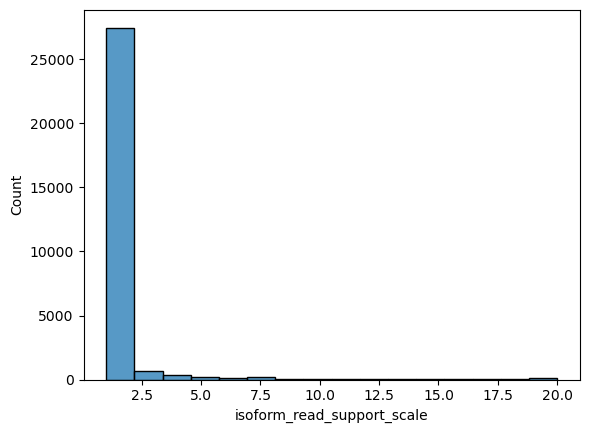

In [75]:
sns.histplot(anti["isoform_read_support_scale"], common_norm=False)
#sns.displot(anti["isoform_read_support_scale"], kind="kde", common_norm=False)

### get max read support per gene

In [82]:
anti_gene=anti[["accession","gene","gene_read_support"]].drop_duplicates()
anti_gene["gene_read_support_scale"]=anti_gene["gene_read_support"]
anti_gene[anti_gene["gene_read_support_scale"]>20]=20

<AxesSubplot:xlabel='gene_read_support_scale', ylabel='Count'>

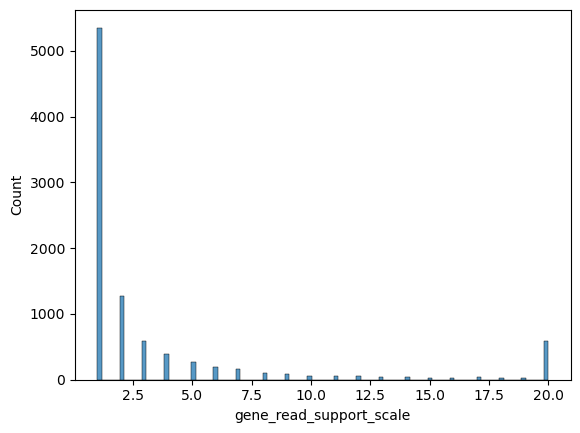

In [84]:
sns.histplot(anti_gene["gene_read_support_scale"], common_norm=False)

## Handle new genes

In [76]:
novel=ref.loc[ref["cat_assign"]=="novel"].copy()
novel

,gene,isoform,accession,associated_gene,associated_transcript,exons,length,isoform_read_support,gene_read_support,structural_category,subcategory,Sqanti_ORF_seq,cat_assign,association,cat_read_support,gene_association_read_support
969,G1065,G1065.1,at6923,novelGene_32,novel,1,507,1,1,intergenic,mono-exon,NaN,novel,2,1,1
1151,G1085,G1085.1,at6923,novelGene_33,novel,4,436,1,3,intergenic,multi-exon,NaN,novel,2,3,1
1152,G1085,G1085.2,at6923,novelGene_34,novel,4,389,2,3,intergenic,multi-exon,NaN,novel,2,3,2
2494,G116,G116.1,at6923,novelGene_2,novel,1,641,1,512,intergenic,mono-exon,NaN,novel,2,1,1
4139,G1254,G1254.56,at6923,novelGene_35,novel,1,212,1,69,intergenic,mono-exon,NaN,novel,2,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
161834,G16250,G16250.47,col0,novelGene_1541,novel,1,1386,2,77,intergenic,mono-exon,NaN,novel,2,56,2
161835,G16250,G16250.48,col0,novelGene_1542,novel,1,1414,1,77,intergenic,mono-exon,NaN,novel,2,56,1
161836,G16250,G16250.49,col0,novelGene_1543,novel,1,1469,6,77,intergenic,mono-exon,NaN,novel,2,56,6
161838,G16250,G16250.50,col0,novelGene_1544,novel,1,1136,1,77,intergenic,mono-exon,NaN,novel,2,56,1


In [77]:
novel["isoform_read_support_scale"]=novel["isoform_read_support"]
novel[novel["isoform_read_support_scale"]>20]=20

<AxesSubplot:xlabel='isoform_read_support_scale', ylabel='Count'>

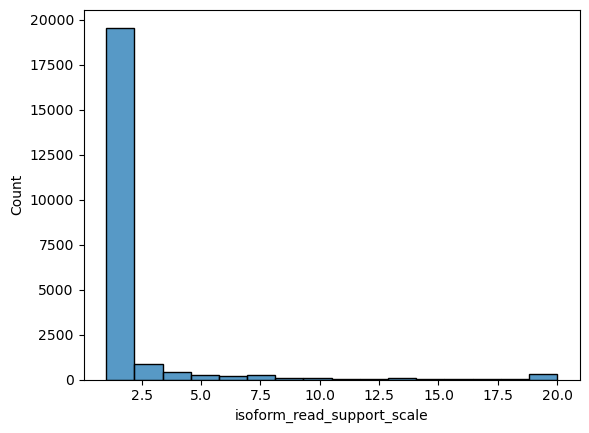

In [85]:
sns.histplot(novel["isoform_read_support_scale"], common_norm=False)

In [86]:
novel_gene=novel[["accession","gene","gene_read_support"]].drop_duplicates()
novel_gene["gene_read_support_scale"]=novel_gene["gene_read_support"]
novel_gene[novel_gene["gene_read_support_scale"]>20]=20

In [105]:
print([*range(20)])

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


/ebio/abt6/lvaness/anaconda3/envs/jupyter/lib/python3.10/site-packages/seaborn/_decorators.py:36: FutureWarning: Pass the following variable as a keyword arg: x. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  warnings.warn(


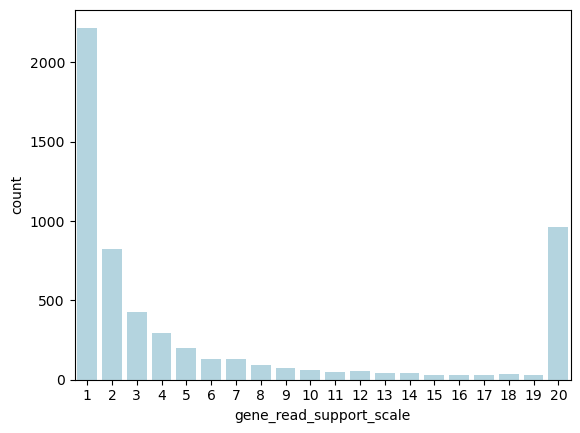

In [131]:
#https://seaborn.pydata.org/generated/seaborn.histplot.html
g=sns.countplot(novel_gene["gene_read_support_scale"], color="lightblue")